In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from astropy.io import fits
from scipy import ndimage as ndi
import matplotlib.pyplot as plt

In [2]:
def percentile_norm(img, pmin=1, pmax=99):
    x = np.array(img, dtype=float, copy=True)
    x[~np.isfinite(x)] = np.nan

    lo, hi = np.nanpercentile(x, [pmin, pmax])
    x = (x - lo) / (hi - lo)
    x = np.clip(x, 0, 1)
    return x 

In [3]:
def weighted_center(labels_data, region_id, image, label_slices):
    slc = label_slices[region_id - 1]

    mask = labels_data[slc] == region_id
    img = np.asarray(image[slc], dtype=float)

    weights = img.copy()
    weights[~mask] = 0.0
    weights[~np.isfinite(weights)] = 0.0
    weights[weights < 0] = 0.0

    total = weights.sum()

    yy, xx = np.indices(weights.shape)

    x = (xx * weights).sum() / total + slc[1].start
    y = (yy * weights).sum() / total + slc[0].start

    return x, y

In [4]:
def plot_region_centers_crop(labels_data, region_id, image, centers, pad=40):
    slc = label_slices[region_id - 1]

    yslice, xslice = slc
    ny, nx = image.shape

    y0 = max(yslice.start - pad, 0)
    y1 = min(yslice.stop  + pad, ny)
    x0 = max(xslice.start - pad, 0)
    x1 = min(xslice.stop  + pad, nx)

    crop_slc = np.s_[y0:y1, x0:x1]

    img_crop = image[crop_slc]
    mask_crop = labels_data[crop_slc] == region_id

    plt.figure(figsize=(7, 7))
    plt.imshow(percentile_norm(img_crop), origin="lower", cmap="gray")

    plt.contour(
        mask_crop.astype(float),
        levels=[0.5],
        colors="lime",
        linewidths=1.5)

    for label, (x, y, color, marker) in centers.items():
        plt.scatter(
            [x - x0],
            [y - y0],
            s=90,
            marker=marker,
            color=color,
            label=label)

    plt.title(f"Region {region_id}: center comparison")
    plt.legend()
    plt.axis("off")
    plt.show()

In [5]:
def safe_log10_ratio(num, den):
    num = np.asarray(num, dtype=float)
    den = np.asarray(den, dtype=float)

    out = np.full_like(num, np.nan, dtype=float)

    valid = (np.isfinite(num) &
        np.isfinite(den) &
        (num > 0) &
        (den > 0))

    out[valid] = np.log10(num[valid] / den[valid])
    return out

In [6]:
def radial_profile_one_region(
    labels_data,
    region_id,
    x0,
    y0,
    line_maps,
    line_err_maps,
    label_slices,
    pix_scale,
    dr_pix=4.0):
    slc = label_slices[region_id - 1]
    if slc is None:
        return pd.DataFrame()

    mask = labels_data[slc] == region_id

    if not np.any(mask):
        return pd.DataFrame()

    yy, xx = np.indices(mask.shape)

    x0_local = x0 - slc[1].start
    y0_local = y0 - slc[0].start

    r_pix = np.sqrt((xx - x0_local)**2 + (yy - y0_local)**2)

    max_r = np.nanmax(r_pix[mask])
    if not np.isfinite(max_r) or max_r <= 0:
        return pd.DataFrame()

    bin_edges = np.arange(0, max_r + dr_pix, dr_pix)

    img_crops = {name: img[slc] for name, img in line_maps.items()}
    err_crops = {name: err[slc] for name, err in line_err_maps.items()}

    rows = []

    for i in range(len(bin_edges) - 1):
        r_in = bin_edges[i]
        r_out = bin_edges[i + 1]

        ann = mask & (r_pix >= r_in) & (r_pix < r_out)

        n_pix = int(np.sum(ann))
        if n_pix == 0:
            continue

        area_arcsec2 = n_pix * pix_scale**2

        row = {
            "region_id": region_id,
            "bin_id": i,
            "r_in_pix": r_in,
            "r_out_pix": r_out,
            "r_mid_pix": 0.5 * (r_in + r_out),
            "r_in_arcsec": r_in * pix_scale,
            "r_out_arcsec": r_out * pix_scale,
            "r_mid_arcsec": 0.5 * (r_in + r_out) * pix_scale,
            "r_norm": 0.5 * (r_in + r_out) / max_r,
            "n_pix": n_pix,
            "area_arcsec2": area_arcsec2,
        }

        for name in line_maps.keys():
            vals = img_crops[name][ann]
            errs = err_crops[name][ann]

            flux = np.nansum(vals)
            err = np.sqrt(np.nansum(errs**2))

            row[f"{name}_flux"] = flux
            row[f"{name}_err"] = err
            row[f"{name}_sn"] = flux / err if err > 0 else np.nan
            row[f"{name}_sb"] = flux / area_arcsec2

        rows.append(row)

    prof = pd.DataFrame(rows)

    if len(prof) == 0:
        return prof

    prof["log_sii_ha"] = safe_log10_ratio(prof["sii_flux"], prof["ha_flux"])
    prof["log_oiii_ha"] = safe_log10_ratio(prof["oiii_flux"], prof["ha_flux"])
    prof["log_sii_oiii"] = safe_log10_ratio(prof["sii_flux"], prof["oiii_flux"])
    prof["log_oiii_hb"] = safe_log10_ratio(prof["oiii_flux"], prof["hb_flux"])
    prof["log_nii_ha"] = safe_log10_ratio(prof["nii_flux"], prof["ha_flux"])

    prof["flag_low_sn_ha"] = prof["ha_sn"] < 3
    prof["flag_low_sn_sii"] = prof["sii_sn"] < 3
    prof["flag_low_sn_oiii"] = prof["oiii_sn"] < 3

    return prof

In [7]:
checkpoint_dir = Path("./results")

cat2 = pd.read_pickle(checkpoint_dir / "first_pass_catalog.pkl")

labels_data = fits.getdata(checkpoint_dir / "labels_data.fits").astype(np.int32)
detection = fits.getdata(checkpoint_dir / "detection.fits")
pn_mask = fits.getdata(checkpoint_dir / "pn_mask.fits").astype(bool)

ha = fits.getdata(checkpoint_dir / "ha.fits")
ha_err = fits.getdata(checkpoint_dir / "ha_err.fits")

hb = fits.getdata(checkpoint_dir / "hb.fits")
hb_err = fits.getdata(checkpoint_dir / "hb_err.fits")

oiii = fits.getdata(checkpoint_dir / "oiii.fits")
oiii_err = fits.getdata(checkpoint_dir / "oiii_err.fits")

nii = fits.getdata(checkpoint_dir / "nii.fits")
nii_err = fits.getdata(checkpoint_dir / "nii_err.fits")

sii = fits.getdata(checkpoint_dir / "sii.fits")
sii_err = fits.getdata(checkpoint_dir / "sii_err.fits")
with open(checkpoint_dir / "metadata.json") as f:
    metadata = json.load(f)

label_slices = ndi.find_objects(labels_data)

In [8]:
potential_hii = cat2[(~cat2["flag_bad_mask"]) & (~cat2["flag_any_high_bg"]) &
    ((cat2["first_pass_tag"] == "hii_like_candidate") |
    (cat2["first_pass_tag"] == "transition_sii_candidate"))].copy()

print("Potential HII regions:", len(potential_hii))

Potential HII regions: 546


Region: 163
Halpha center: 1905.2324934978008 734.190607465894
Detection center: 1905.3453377183016 734.3960143235212
Geometrical center: 1905 737


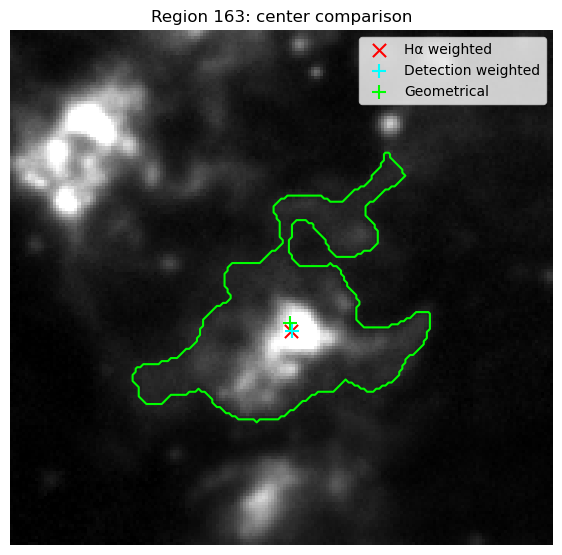

In [19]:
test_id = int(potential_hii.iloc[100]["region_id"])
geo_x, geo_y = int(potential_hii.iloc[100]["x"]), int(potential_hii.iloc[100]["y"])
'''
x_ha_w, y_ha_w = weighted_center(
    labels_data,
    test_id,
    ha,
    label_slices)

x_det_w, y_det_w = weighted_center(
    labels_data,
    test_id,
    detection,
    label_slices)

print("Region:", test_id)
print("Halpha center:", x_ha_w, y_ha_w)
print("Detection center:", x_det_w, y_det_w)
print("Geometrical center:", geo_x, geo_y)

plot_region_centers_crop(
    labels_data,
    test_id,
    ha,
    centers={
        "Hα weighted": (x_ha_w, y_ha_w, "red", "x"),
        "Detection weighted": (x_det_w, y_det_w, "cyan", "+"),
        "Geometrical": (geo_x, geo_y, "lime", "+")}, pad=40)    
'''        

In [20]:
centers = []

for _, row in potential_hii.iterrows():
    region_id = int(row["region_id"])

    x_ha_w, y_ha_w = weighted_center(labels_data, region_id, ha, label_slices)

    centers.append({
        "region_id": region_id,
        "x_ha_w": x_ha_w,
        "y_ha_w": y_ha_w})

centers = pd.DataFrame(centers)

potential_hii = potential_hii.drop(columns=["x_ha_w", "y_ha_w"], errors="ignore")
potential_hii = potential_hii.merge(centers, on="region_id", how="left")

cat2 = cat2.drop(columns=["x_ha_w", "y_ha_w"], errors="ignore")
cat2 = cat2.merge(centers, on="region_id", how="left")

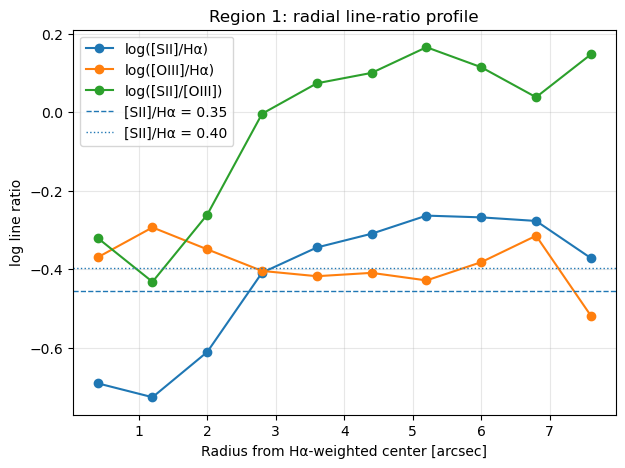

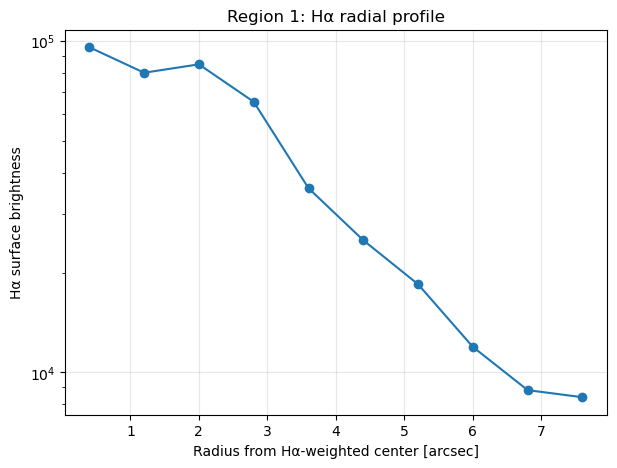

In [23]:
line_maps = {"ha": ha, "hb": hb, "oiii": oiii, "nii": nii, "sii": sii,}
line_err_maps = {"ha": ha_err, "hb": hb_err, "oiii": oiii_err, "nii": nii_err, "sii": sii_err}

pix_scale = metadata["pix_scale_arcsec"]

test_row = potential_hii.iloc[0]
test_id = int(test_row["region_id"])

prof = radial_profile_one_region(
    labels_data=labels_data,
    region_id=test_id,
    x0=test_row["x_ha_w"],
    y0=test_row["y_ha_w"],
    line_maps=line_maps,
    line_err_maps=line_err_maps,
    label_slices=label_slices,
    pix_scale=pix_scale,
    dr_pix=4.0,
)

prof.head()
plt.figure(figsize=(7, 5))

plt.plot(
    prof["r_mid_arcsec"],
    prof["log_sii_ha"],
    marker="o",
    label="log([SII]/Hα)"
)

plt.plot(
    prof["r_mid_arcsec"],
    prof["log_oiii_ha"],
    marker="o",
    label="log([OIII]/Hα)"
)

plt.plot(
    prof["r_mid_arcsec"],
    prof["log_sii_oiii"],
    marker="o",
    label="log([SII]/[OIII])"
)

plt.axhline(np.log10(0.35), linestyle="--", linewidth=1, label="[SII]/Hα = 0.35")
plt.axhline(np.log10(0.40), linestyle=":", linewidth=1, label="[SII]/Hα = 0.40")

plt.xlabel("Radius from Hα-weighted center [arcsec]")
plt.ylabel("log line ratio")
plt.title(f"Region {test_id}: radial line-ratio profile")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
prof["area_arcsec2"] = prof["n_pix"] * pix_scale**2
prof["ha_sb"] = prof["ha_flux"] / prof["area_arcsec2"]

plt.figure(figsize=(7, 5))
plt.plot(
    prof["r_mid_arcsec"],
    prof["ha_sb"],
    marker="o"
)

plt.yscale("log")
plt.xlabel("Radius from Hα-weighted center [arcsec]")
plt.ylabel("Hα surface brightness")
plt.title(f"Region {test_id}: Hα radial profile")
plt.grid(alpha=0.3)
plt.show()